### Surrounded Regions

You are given an m x n matrix board containing letters 'X' and 'O', capture regions that are surrounded:

Connect: A cell is connected to adjacent cells horizontally or vertically.
Region: To form a region connect every 'O' cell.
Surround: A region is surrounded if none of the 'O' cells in that region are on the edge of the board. Such regions are completely enclosed by 'X' cells.
To capture a surrounded region, replace all 'O's with 'X's in-place within the original board. You do not need to return anything.

Example 1:

Input: board = [["X","X","X","X"],["X","O","O","X"],["X","X","O","X"],["X","O","X","X"]]

Output: [["X","X","X","X"],["X","X","X","X"],["X","X","X","X"],["X","O","X","X"]]

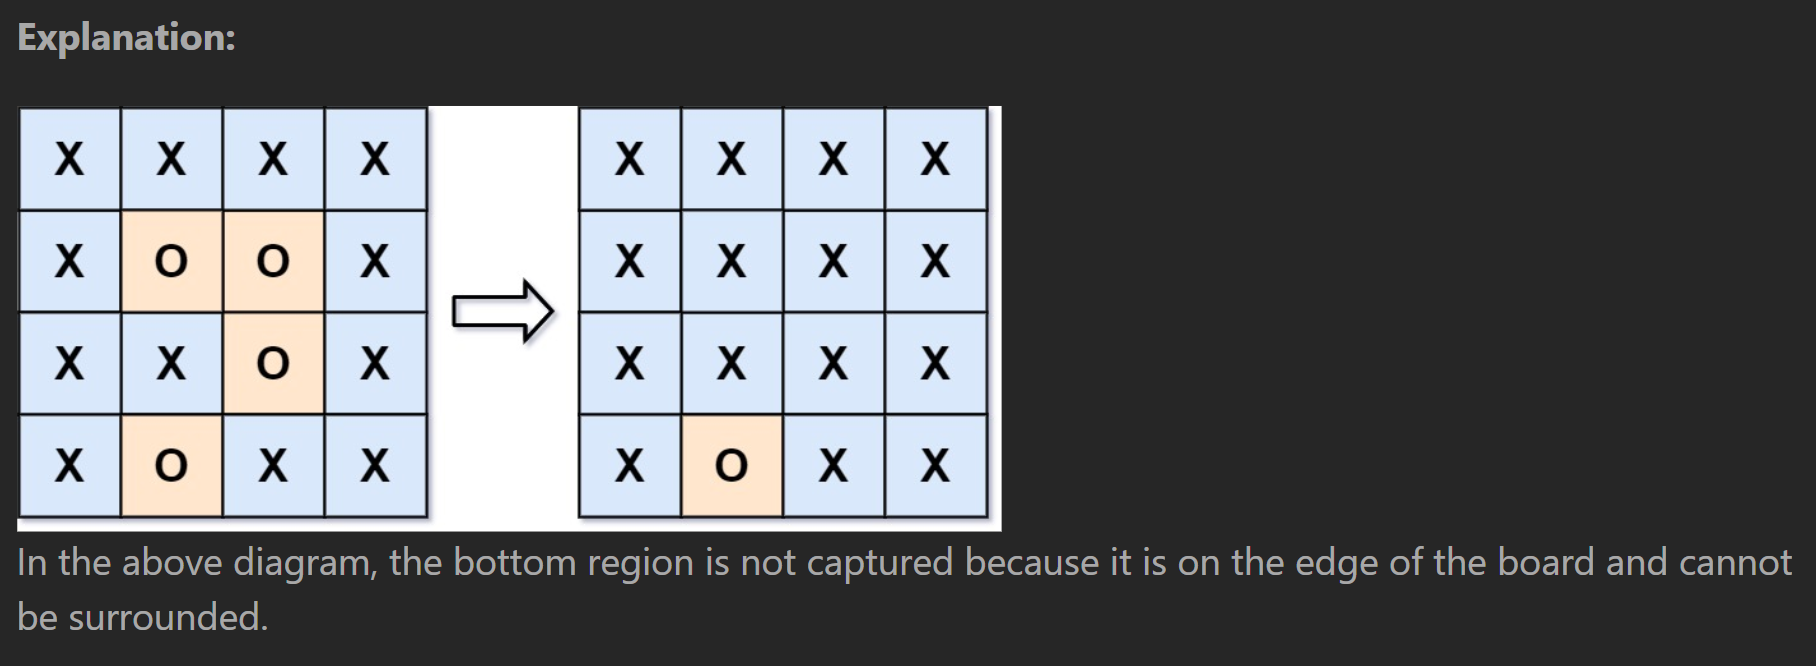

We cannot even capture any cell which is 0 and is attached to the edge
We need to exclude all such cells
So we reverse bfs this shit

In [1]:
from collections import deque

In [ ]:
class Solution:
    def solve(self, board: list[list[str]]) -> None:
        """
        Do not return anything, modify board in-place instead.
        """

        # define a get neighbors function
        def get_neighbors(r, c):
            rows = len(board)
            cols = len(board[0])
            neighbors = []
            directions = [
                (-1,0),
                (0, 1),
                (1, 0),
                (0,-1)
            ]
            for dr, dc in directions:
                nr = r + dr
                nc = c + dc
                # step 1, make sure that they are within the index bounds
                if 0<=nr<rows and 0<=nc<cols: 
                    # step 2: we ensure that they are O on the board
                    if board[nr][nc] == 'O':
                        neighbors.append((nr, nc))

            return neighbors

        visited = set() 
        def bfs(source_r, source_c):
            queue = deque([(source_r, source_c)])
            visited.add((source_r, source_c))

            while queue:
                popped_node_r, popped_node_c = queue.popleft()
                for r, c in get_neighbors(popped_node_r, popped_node_c):
                    if (r,c) not in visited:
                        queue.append((r,c))
                        visited.add((r,c))

        # now that we have defined the get_neighbors function and that we have bfs function
        # we call the bfs on all the edge cells provided any one of them is a O
        for r in range(len(board)):
            for c in range(len(board[0])):

                if r == 0 or r == len(board)-1 or c == 0 or c == len(board[0]) - 1:
                    if board[r][c] == 'O':
                        if (r,c) not in visited:
                            bfs(r,c)

        # now visited will contain all the cells that cannot be replaced by an X
        for r in range(len(board)):
            for c in range(len(board[0])):
                if (r,c) not in visited:
                    board[r][c] = 'X'
